# DiscoCH: near-real-time vs. all-data season
Reruns a finished season with every Sentinel-2 observation and compares it with the near-real-time series from `DiscoCH.ipynb`:

- **Near real time (5-day lag):** each date is interpolated from observations up to 5 days after it (`DiscoCH.ipynb`).
- **All data:** each date is interpolated from all observations within the RBF kernel, before and after it.

Both are normalized with the same stepwise min/max: the near-real-time run's per-date snapshots (`minmax_by_date/`), so nothing after a date enters its min/max and only the interpolation differs.

*Run `DiscoCH.ipynb` up to and including Masking first (with `export_minmax=True`), at the end of the season.*

In [5]:
# User defined parameters -- same as DiscoCH.ipynb
force_directory = r'B:\bloomc\DiscoCH_2026_08_03\FORCE\level3_tss'  # Local FORCE VI data (synced by DiscoCH.ipynb)
output_dir = "../output"  # Where to save output data
force_tiles_to_process = r"..\data\CH_FORCE_Grids.csv"  # Tiles to process (Tile_ID column)
disco_model = r"..\data\empirical_discoloration_model_pipeline_2025_6_2.pkl"  # Pre-trained Discoloration Model
mask_path = r"..\data\DiscoCH_2026_Mask.tif"
year = 2026

# Same RBF settings and VI naming as the near-real-time run
rbf_sigma = (10, 20, 30)
vi_keys = {
    "NDVI": "NDVI",
    "EVI": "EVI",
    "NDMI": "NDMI",
    "CIRE": "CIre",
    "CCI": "CCI",
}

In [6]:
# Libraries
import os
from datetime import date
import matplotlib.pyplot as plt

from src.disco_ch_operational.interpolate import run_full_data_season
from src.disco_ch_operational.mask import mask_and_scale_dir
from src.disco_ch_operational.compare import plot_year_comparison

# Reset to the standard light theme for plots
plt.style.use('default')

# Explicitly force figures to white:
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'

# Folders: near-real-time (from DiscoCH.ipynb) and all-data (written here)
force_output = os.path.join(output_dir, 'DiscoCH_rbf_10_20_30')
nrt_output = os.path.join(force_output, str(year))
nrt_masked = os.path.join(nrt_output, 'masked')
full_rbf_output = os.path.join(force_output, 'level4_rbf_full_data', str(year))
full_output = os.path.join(force_output, f'{year}_full_data')
full_masked = os.path.join(full_output, 'masked')
stats_output = os.path.join(full_output, 'statistics')

## Interpolate with all data and apply the model

In [4]:
# 1) RBF with every observation (as_of=None), 2) model normalized with the
# near-real-time min/max of each date. Re-running skips finished files/dates.
interpolated, summary = run_full_data_season(
    tss_dir=force_directory,
    rbf_dir=full_rbf_output,
    out_dir=full_output,             # tiles, mosaic/, logs/
    nrt_out_dir=nrt_output,          # its minmax_by_date/ gives each date's min/max
    year=year,
    model_path=disco_model,
    vi_keys=vi_keys,
    date_range=(date(year, 1, 1), date(year, 12, 31)),  # same 5-day grid as the near-real-time run
    rbf_sigma=rbf_sigma, rbf_cutoff=0.95,
    tiles_csv=force_tiles_to_process,
    model_months=(6, 7, 8, 9),
    max_workers=10,
)

=== 1/2 Interpolating 2026 with all observations -> ../output\DiscoCH_rbf_10_20_30\level4_rbf_full_data\2026
  tiles_csv (CH_FORCE_Grids.csv, include): 69 of 70 tile(s) selected
Found 69 tile(s) under B:\bloomc\DiscoCH_2026_08_03\FORCE\level3_tss
  [1/345, 0:00, ~3:24 left] X0051_Y0066/NDVI: skipped
  [2/345, 0:00, ~1:44 left] X0051_Y0066/EVI: skipped
  [3/345, 0:00, ~1:09 left] X0052_Y0065/NDVI: skipped
  [4/345, 0:00, ~0:52 left] X0052_Y0065/EVI: skipped
  [5/345, 0:00, ~0:41 left] X0052_Y0065/NDMI: skipped
  [6/345, 0:00, ~0:34 left] X0052_Y0065/CIRE: skipped
  [7/345, 0:00, ~0:29 left] X0051_Y0066/NDMI: skipped
  [8/345, 0:00, ~0:25 left] X0052_Y0065/CCI: skipped
  [9/345, 0:00, ~0:22 left] X0052_Y0066/NDVI: skipped
  [10/345, 0:00, ~0:20 left] X0052_Y0066/EVI: skipped
  [11/345, 0:00, ~0:18 left] X0052_Y0066/NDMI: skipped
  [12/345, 0:00, ~0:17 left] X0051_Y0066/CIRE: skipped
  [13/345, 0:00, ~0:15 left] X0052_Y0066/CIRE: skipped
  [14/345, 0:00, ~0:14 left] X0053_Y0063/NDVI: skip

## Masking

In [6]:
# Same mask and scaling as the near-real-time mosaics
status = mask_and_scale_dir(input_dir=os.path.join(full_output, 'mosaic'),
                            mask_path=mask_path,
                            output_dir=full_masked,
                            pattern='Disco_Proba_*.tif',
                            threads=4,
                            )

Loading mask ..\data\DiscoCH_2026_Mask.tif on its grid in EPSG:2056 ...
  34842 x 22066 px, 3.3% kept
  Disco_Proba_2026-06-05.tif: written (scale 10000)
  Disco_Proba_2026-08-14.tif: written (scale 10000)
  Disco_Proba_2026-08-29.tif: written (scale 10000)
Done in 1:44: 21 skipped, 3 written


## Spatiotemporal Statistics

Counting 24 mosaics in ../output\DiscoCH_rbf_10_20_30\2026\masked (34842 x 22066 px), threshold >= 4000 ...
Done in 0:25
Counting 24 mosaics in ../output\DiscoCH_rbf_10_20_30\2026_full_data\masked (34842 x 22066 px), threshold >= 4000 ...
Done in 0:26
Counting 24 mosaics in B:\bloomc\JAG_Manuscript_2026_03_10\JAG_DiscoCH\output\disco_predictions\2026_03_21\mosaics (39000 x 24000 px), threshold >= 4000 ...
Done in 0:28
Saved ../output\DiscoCH_rbf_10_20_30\2026_full_data\statistics\discoloration_comparison_2026_nrt_vs_full_data.png and discoloration_comparison_2026_nrt_vs_full_data.csv


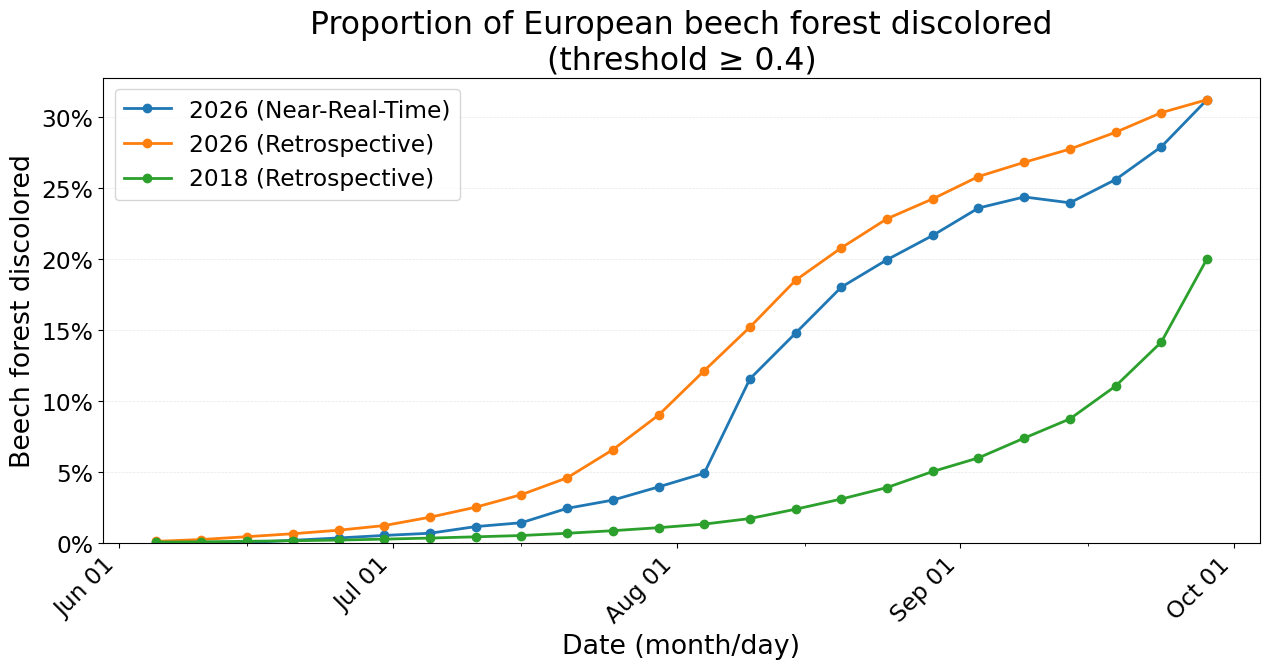

In [9]:
# Same plot as DiscoCH.ipynb, with the all-data series added
mosaics_2018 = r"B:\bloomc\JAG_Manuscript_2026_03_10\JAG_DiscoCH\output\disco_predictions\2026_03_21\mosaics"
threshold = 4000  # Stored value (0-10000) at/above which a pixel is discolored: 4000 = 40 % probability

comparison = plot_year_comparison(
    {
        f"{year} (Near-Real-Time)": dict(mosaic_dir=nrt_masked, year=year),
        f"{year} (Retrospective)": dict(mosaic_dir=full_masked, year=year),
        "2018 (Retrospective)": dict(mosaic_dir=mosaics_2018, pattern="Proba_mosaic_*.tif", year=2018),
    },
    threshold=threshold,
    output_dir=stats_output,
    output_name=f"discoloration_comparison_{year}_nrt_vs_full_data",
    max_workers=8,
)

In [11]:
# Difference per date: all data minus near real time
total = comparison[comparison.zone == "All"].pivot(index="date", columns="dataset", values="proportion")
diff = (total[f"{year} (Retrospective)"] - total[f"{year} (Near-Real-Time)"]).dropna()
print(diff.rename("retrospective - near-real-time (proportion)").round(4).to_string())

date
2026-06-05    0.0010
2026-06-10    0.0023
2026-06-15    0.0041
2026-06-20    0.0046
2026-06-25    0.0055
2026-06-30    0.0070
2026-07-05    0.0113
2026-07-10    0.0137
2026-07-15    0.0198
2026-07-20    0.0215
2026-07-25    0.0355
2026-07-30    0.0506
2026-08-04    0.0722
2026-08-09    0.0365
2026-08-14    0.0373
2026-08-19    0.0277
2026-08-24    0.0289
2026-08-29    0.0258
2026-09-03    0.0222
2026-09-08    0.0244
2026-09-13    0.0379
2026-09-18    0.0333
2026-09-23    0.0240
2026-09-28    0.0000


### Per biogeographic region: 2026 vs. 2018
One colour per region (`DERegionNa`, polygons with the same name merged; "All" = Switzerland in black), solid = 2026, dashed = 2018. Both years are counted per region here, so this takes a while.

Counting 24 mosaics in ../output\DiscoCH_rbf_10_20_30\2026\masked (34842 x 22066 px, 6 zones), threshold >= 4000 ...
Done in 1:47
Counting 24 mosaics in B:\bloomc\JAG_Manuscript_2026_03_10\JAG_DiscoCH\output\disco_predictions\2026_03_21\mosaics (39000 x 24000 px, 6 zones), threshold >= 4000 ...
Done in 1:47
Saved ../output\DiscoCH_rbf_10_20_30\2026_full_data\statistics\discoloration_comparison_2026_vs_2018_biogeo_regions_NRT.png and discoloration_comparison_2026_vs_2018_biogeo_regions_NRT.csv


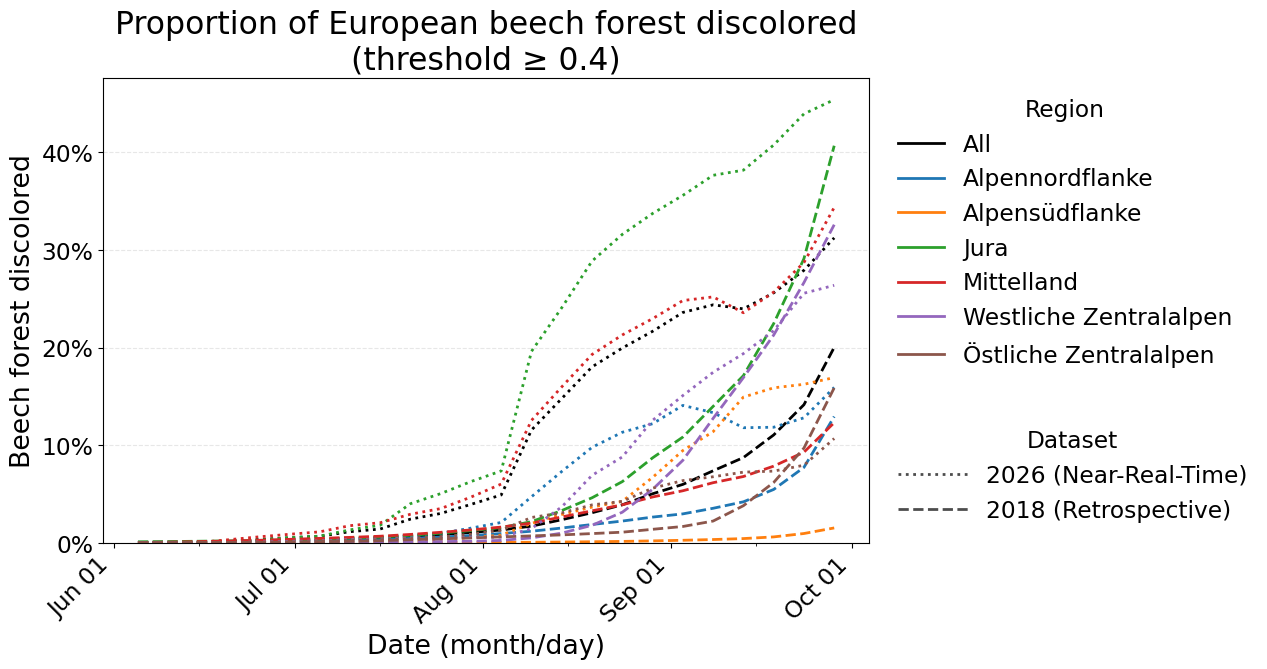

In [8]:
import geopandas as gpd

# UTF-8 as its .CPG says (the default); encoding="cp1252" would garble the umlauts
biogeo_regions = gpd.read_file(
    r"B:\bloomc\DiscoCH_2026_08_03\Viz\biogeographische_regionen_2056.shp\N2020_Revision_BiogeoRegion.shp")
mosaics_2018 = r"B:\bloomc\JAG_Manuscript_2026_03_10\JAG_DiscoCH\output\disco_predictions\2026_03_21\mosaics"
threshold = 4000  # 4000 = 40 % probability

by_region = plot_year_comparison(
    {
        # f"{year} (Retrospective)": dict(mosaic_dir=full_masked, year=year),
        f"{year} (Near-Real-Time)": dict(mosaic_dir=nrt_masked, year=year),
        "2018 (Retrospective)": dict(mosaic_dir=mosaics_2018, pattern="Proba_mosaic_*.tif", year=2018),
    },
    zones=biogeo_regions, zone_field="DERegionNa",   # regions = All + every DERegionNa
    linestyles={f"{year} (Retrospective)": "-", f"{year} (Near-Real-Time)": ":", "2018 (Retrospective)": "--"},
    layout="overlay",                               # or "panels": one panel per region
    threshold=threshold,
    output_dir=stats_output,
    output_name=f"discoloration_comparison_{year}_vs_2018_biogeo_regions_NRT",
    max_workers=8,
)